# 07 Haze: does the 13-band advantage hold in hazy images?

**Purpose.** Answer SQ4: does the 13-band advantage still hold when the images are hazy, both with haze that affects every band equally and with haze that, as in reality, affects short wavelengths most? The saved models of notebooks 03 to 05 predict the same test patches with simulated haze of increasing thickness; nothing is retrained.

**Functions.** `src/piece_of_crop/haze.py` (`haze_share`, `add_haze`, `hazy_test_loader`, `rf_hazy_probabilities`, `WAVELENGTHS_NM`), `evaluate.py` (`insurer_cost_matrix`, `block_bootstrap_ci`, `caught_by_review`), the model loading in `haze.py` (`load_saved_model`, `hazy_probabilities`), `train.py` (`predict`), `cnn.py` (`SmallCNN`) and `resnet.py` (`build_resnet`, `IMAGE_SIZE`).

**Reads.** `results/split.csv`, `results/band_stats.csv`, the clean test predictions in `results/predictions/`, the 18 saved models in `models/` and the patch cache `data/eurosat_cache.npy`.

**Saves.** `results/haze_runs.csv`, `results/haze_differences.csv`, `results/haze_review.csv`, `results/haze_destinations.csv` and the figures `results/figures/haze_*.png`. The predictions on hazy patches are not saved per patch, because the summary tables hold everything the report uses.

## 1. Setup

In [1]:
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
from IPython.display import display

from piece_of_crop import BAND_NAMES, CLASS_NAMES, MODEL_FILES, RGB_BAND_INDICES, read_split, get_cache
from piece_of_crop import SmallCNN, build_resnet, IMAGE_SIZE, predict
from piece_of_crop import WAVELENGTHS_NM, haze_share, add_haze, hazy_test_loader, rf_hazy_probabilities
from piece_of_crop import insurer_cost_matrix, block_bootstrap_ci, caught_by_review
from piece_of_crop import load_saved_model, hazy_probabilities

SEEDS = (0, 1, 2)
INPUTS = ("rgb", "13band")
MODELS = tuple(MODEL_FILES)  # RandomForest, SmallCNN, ResNet18
PROFILES = ("uniform", "wavelength")
HAZE_LEVELS = (0.01, 0.02, 0.05, 0.10, 0.20, 0.40, 0.63)  # share of haze at 550 nm, see section 2
N_BOOTSTRAP = 2000
BOOTSTRAP_SEED = 0

project_root = Path.cwd().parents[0]
data_dir = project_root / "data" / "EuroSAT_MS"
results_dir = project_root / "results"
figures_dir = results_dir / "figures"
predictions_dir = results_dir / "predictions"
models_dir = project_root / "models"

split = read_split(results_dir / "split.csv")
band_stats = pd.read_csv(results_dir / "band_stats.csv")
cache = get_cache(split, data_dir, project_root / "data" / "eurosat_cache.npy")
test_rows = split[split["split"].eq("test")].reset_index(drop=True)
y_true = test_rows["label"].to_numpy()
blocks = test_rows["block"].to_numpy()
label_ids = np.arange(len(CLASS_NAMES))
costs = insurer_cost_matrix()
critical = costs >= 8  # as in notebook 06
airlight = band_stats["clip_high"].to_numpy(dtype=np.float32)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

print("Device:", device, "| test patches:", len(test_rows))

Device: mps | test patches: 3854


## 2. The haze model

**Claim.** We simulate haze with the standard model of a hazy image, with the haze per band set by physics, so that every step can be checked. The strength of the haze is a share we choose, not a measured haze level.

**How it works.** A hazy value is the clear value seen through the haze plus the light that the haze itself scatters towards the sensor:

hazy = (1 − share) × clear + share × airlight

This is the model "widely used to describe the formation of a hazy image" (external: He, Sun and Tang, 2011, "Single Image Haze Removal Using Dark Channel Prior", *IEEE TPAMI* 33(12), equation 1). We build it from three parts:

1. **Strength: the share of haze at 550 nm** (green light), at seven levels: 1%, 2%, 5%, 10%, 20%, 40% and 63%. Each step is at most about twice the one before, and most lie below 20%, where the first version showed the models starting to fail (see below).
2. **Haze per band: the Ångström law.** Haze scatters short wavelengths more: the optical depth at wavelength λ is the optical depth at 550 nm × (λ / 550 nm)^−α. The exponent was introduced by Ångström in 1929, and its average for natural atmospheres is about 1.3, within a typical range of 0.5 to 2.5 (external: instesre.org/Aerosols/angstrom.htm). The central wavelengths of the bands are those published by the USGS (external: USGS EROS Archive, Sentinel-2).
3. **From optical depth to share.** Light that crosses a layer of optical depth τ is reduced to exp(−τ) of its strength on a vertical path (Beer–Lambert law; external: Penn State, METEO 300, section 6.10). It crosses the haze twice, from the sun to the ground and back up, so the share of haze in a band is 1 − exp(−2τ). The table below shows the result: at 20% in green, blue (B02) gets 23% and B12 only 4%.

The **airlight** is the brightness of the haze itself. We set it to the brightest normal value of each band, the training 99.9th percentile from notebook 02, so that thick haze turns a patch bright and pale. The **uniform** profile gives every band the share of 550 nm. It is not realistic; it is a control. If the 13 bands hold up better only under the wavelength profile, the reason is that the infrared bands see through the haze, not that there are more bands.

Haze is added to the raw bands, which are then clipped and normalised with the clean training statistics, exactly what a deployed model would receive. No model is retrained, as in the course's adversarial examples, where a trained model is given "slightly modified" inputs to see whether its predictions change (lecture_15_intro_to_generative_models.pdf, slide 8).

**Why the strength is a share and not a real haze measure.** Our first version expressed the strength as aerosol optical depth (AOD), the standard measure of haze, at four levels taken from a NOAA guide: 0.1 (clean), 0.3 (thin), 0.5 (moderately thick) and 0.8 (thick). Its results showed that this scale was wrong in our model. At AOD 0.1, which NOAA calls a clean atmosphere, the 13-band CNN dropped from 95% to 44% accuracy, and the example patch was already washed out at AOD 0.3, which real satellite images on such a day are not. The reason is the airlight: the haze model comes from photographs taken along the ground, where haze in front of a distant hill is as bright as the horizon sky, while a satellite looks straight down through a thin layer whose scattered light is much dimmer. Our bright airlight, and leaving out the scattered light that still reaches the sensor, make the haze several times too strong for a given AOD. We therefore report the strength as the share of haze at 550 nm and make no claim about which real AOD each level matches. The highest level, 63%, equals the old AOD 0.5. The first version is kept in the project history (Git commit 14e3979).

**Counterargument.** Without a calibrated scale, we cannot say how hazy a real day must be for a model to fail, only how the models and inputs compare as the haze grows. We accept this: SQ4 asks whether the 13-band advantage holds under haze, which is a comparison, and both inputs get exactly the same haze.

Share of haze in each band (bands in wavelength order):


,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B10,B11,B12
"uniform, 1%",0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01
"uniform, 2%",0.02,0.02,0.02,0.02,0.02,0.02,0.02,0.02,0.02,0.02,0.02,0.02,0.02
"uniform, 5%",0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05
"uniform, 10%",0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10
"uniform, 20%",0.20,0.20,0.20,0.20,0.20,0.20,0.20,0.20,0.20,0.20,0.20,0.20,0.20
"uniform, 40%",0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40
"uniform, 63%",0.63,0.63,0.63,0.63,0.63,0.63,0.63,0.63,0.63,0.63,0.63,0.63,0.63
"wavelength, 1%",0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.00,0.00,0.00,0.00
"wavelength, 2%",0.03,0.02,0.02,0.02,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.00,0.00
"wavelength, 5%",0.07,0.06,0.05,0.04,0.04,0.03,0.03,0.03,0.03,0.03,0.02,0.01,0.01


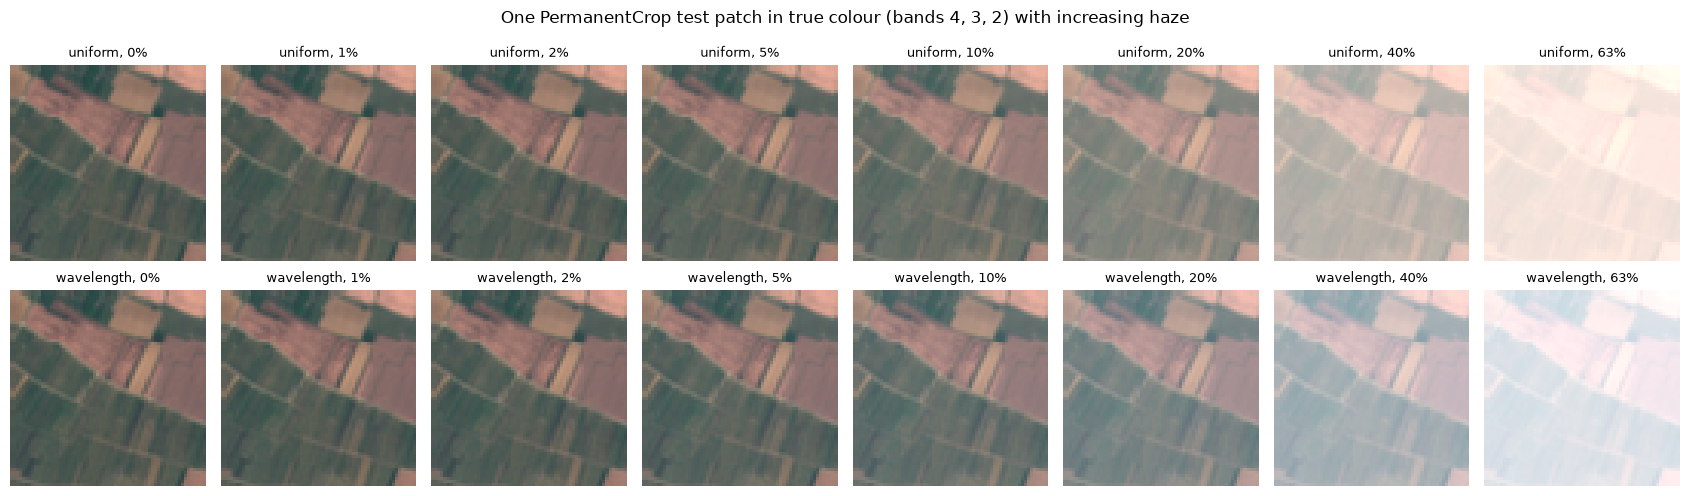

In [2]:
# share of each band's value that comes from the haze, (1 - t)
share_table = pd.DataFrame({f"{profile}, {strength:.0%}": haze_share(strength, profile) for profile in PROFILES for strength in HAZE_LEVELS},
                           index=BAND_NAMES).T
order = [BAND_NAMES[k] for k in np.argsort(WAVELENGTHS_NM)]
print("Share of haze in each band (bands in wavelength order):")
display(share_table[order].round(2))

# one patch at every level, on a fixed display scale so the haze is visible
example = int(np.where(y_true == CLASS_NAMES.index("PermanentCrop"))[0][0])
clear = np.asarray(cache[test_rows["cache_row"][example]], dtype=np.float32)
fig, axes = plt.subplots(2, len(HAZE_LEVELS) + 1, figsize=(17, 5.2))
for row, profile in enumerate(PROFILES):
    for col, strength in enumerate((0.0,) + HAZE_LEVELS):
        image = add_haze(clear, strength, profile, airlight)[RGB_BAND_INDICES].transpose(1, 2, 0)
        axes[row, col].imshow(np.clip(image / 3000, 0, 1))
        axes[row, col].set_title(f"{profile}, {strength:.0%}", fontsize=9)
        axes[row, col].axis("off")
fig.suptitle("One PermanentCrop test patch in true colour (bands 4, 3, 2) with increasing haze")
fig.tight_layout()
fig.savefig(figures_dir / "haze_example_patch.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Predict every saved model on the hazy test patches

For each of the 18 saved models (3 models x 2 inputs x 3 seeds), the clean test set is predicted first and compared with the predictions saved in notebooks 03 to 05: they must agree, otherwise the haze results would not be comparable with notebook 06. Then each model predicts the test set at the seven haze levels of both profiles. For every run we keep accuracy, macro-F1, the critical-error rate and cost per patch of notebook 06, and how often HerbaceousVegetation is called Forest, the confusion that notebook 06 linked to the extra bands.

In [3]:
def load_model(model, input_type, seed):
    prefix = MODEL_FILES[model]
    if model == "RandomForest":
        forest = joblib.load(models_dir / f"{prefix}_{input_type}_seed{seed}.joblib")
        assert list(forest.classes_) == list(label_ids)  # probability columns are classes 0 to 9
        return forest
    channels = 3 if input_type == "rgb" else 13
    net = SmallCNN(in_channels=channels, num_classes=len(CLASS_NAMES)) if model == "SmallCNN" else \
        build_resnet(in_channels=channels, num_classes=len(CLASS_NAMES), pretrained=False)
    net.load_state_dict(torch.load(models_dir / f"{prefix}_{input_type}_seed{seed}.pt", map_location="cpu"))
    return net.to(device)


def predict_hazy(model_name, model, input_type, strength, profile):
    if model_name == "RandomForest":
        return rf_hazy_probabilities(model, test_rows, cache, band_stats, input_type, strength, profile, airlight).argmax(axis=1)
    image_size = IMAGE_SIZE if model_name == "ResNet18" else None
    loader = hazy_test_loader(test_rows, cache, band_stats, input_type, strength, profile, airlight, image_size)
    labels, proba = predict(model, loader, device)
    assert np.array_equal(labels, y_true)  # same patches in the same order
    return proba.argmax(axis=1)


herb, forest_id = CLASS_NAMES.index("HerbaceousVegetation"), CLASS_NAMES.index("Forest")
hazy_predictions, run_rows = {}, []
for model_name in MODELS:
    for input_type in INPUTS:
        for seed in SEEDS:
            start = time.time()
            model = load_model(model_name, input_type, seed)
            saved = pd.read_csv(predictions_dir / f"{MODEL_FILES[model_name]}_{input_type}_seed{seed}.csv")["y_pred"].to_numpy()
            clean = predict_hazy(model_name, model, input_type, 0.0, "uniform")
            agreement = (clean == saved).mean()
            assert agreement >= 0.999, f"clean predictions differ from the saved ones ({agreement:.4f})"
            conditions = [("none", 0.0, clean)] + [(profile, strength, predict_hazy(model_name, model, input_type, strength, profile))
                                                   for profile in PROFILES for strength in HAZE_LEVELS]
            for profile, strength, y_pred in conditions:
                hazy_predictions[(model_name, input_type, seed, profile, strength)] = y_pred
                run_rows.append({"model": model_name, "input": input_type, "seed": seed, "profile": profile, "haze_550": strength,
                                 "accuracy": accuracy_score(y_true, y_pred),
                                 "macro_f1": f1_score(y_true, y_pred, average="macro"),
                                 "critical_error_rate": critical[y_true, y_pred].mean(),
                                 "cost_per_patch": costs[y_true, y_pred].mean(),
                                 "herb_called_forest": int(((y_true == herb) & (y_pred == forest_id)).sum())})
            print(f"{model_name} {input_type} seed {seed}: clean agreement {agreement:.4f}, {time.time() - start:.0f} s")

haze_runs = pd.DataFrame(run_rows)
haze_runs.to_csv(results_dir / "haze_runs.csv", index=False)

RandomForest rgb seed 0: clean agreement 1.0000, 15 s
RandomForest rgb seed 1: clean agreement 1.0000, 13 s
RandomForest rgb seed 2: clean agreement 1.0000, 13 s
RandomForest 13band seed 0: clean agreement 1.0000, 13 s
RandomForest 13band seed 1: clean agreement 1.0000, 13 s
RandomForest 13band seed 2: clean agreement 1.0000, 13 s
SmallCNN rgb seed 0: clean agreement 1.0000, 18 s
SmallCNN rgb seed 1: clean agreement 1.0000, 19 s
SmallCNN rgb seed 2: clean agreement 1.0000, 16 s
SmallCNN 13band seed 0: clean agreement 1.0000, 19 s
SmallCNN 13band seed 1: clean agreement 1.0000, 19 s
SmallCNN 13band seed 2: clean agreement 1.0000, 19 s
ResNet18 rgb seed 0: clean agreement 1.0000, 144 s
ResNet18 rgb seed 1: clean agreement 1.0000, 152 s
ResNet18 rgb seed 2: clean agreement 1.0000, 164 s
ResNet18 13band seed 0: clean agreement 1.0000, 250 s
ResNet18 13band seed 1: clean agreement 1.0000, 259 s
ResNet18 13band seed 2: clean agreement 1.0000, 256 s


**Check.** All 18 models predict the clean test set exactly as in notebooks 03 to 05 (agreement 1.0000 for every model), so the haze results below start from the same clean results as notebook 06, and any change comes from the haze alone.

## 4. Accuracy and critical errors as the haze thickens

Mean over the three seeds. 0% is the clean test set; solid lines are 13 bands, dashed lines RGB. The grey area from 40% marks where most models are below 50% accuracy: the points there show that the models have failed, not how well they work.

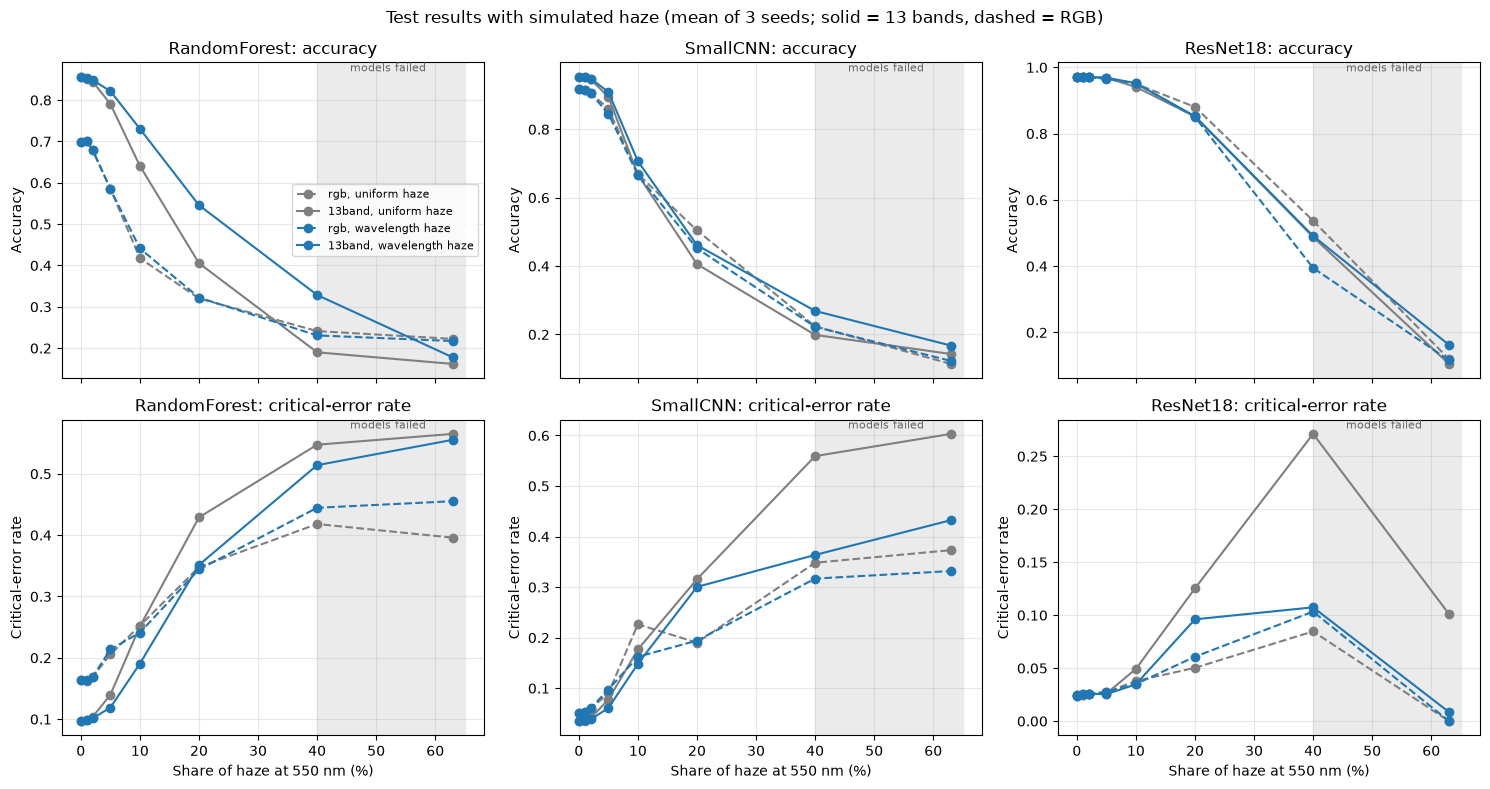

input                               rgb  13band
model        profile    haze_550               
RandomForest uniform    0.00      0.698   0.857
                        0.01      0.702   0.852
                        0.02      0.678   0.845
                        0.05      0.586   0.791
                        0.10      0.418   0.641
                        0.20      0.320   0.406
                        0.40      0.241   0.190
                        0.63      0.222   0.162
             wavelength 0.00      0.698   0.857
                        0.01      0.701   0.853
                        0.02      0.680   0.848
                        0.05      0.585   0.822
                        0.10      0.441   0.731
                        0.20      0.322   0.546
                        0.40      0.231   0.329
                        0.63      0.217   0.178
ResNet18     uniform    0.00      0.972   0.972
                        0.01      0.971   0.971
                        0.02      0.970   0.971
                        0.05      0.967   0.968
                        0.10      0.950   0.941
                        0.20      0.881   0.852
                        0.40      0.537   0.488
                        0.63      0.120   0.105
             wavelength 0.00      0.972   0.972
                        0.01      0.971   0.971
                        0.02      0.970   0.970
                        0.05      0.966   0.969
                        0.10      0.952   0.952
                        0.20      0.850   0.853
                        0.40      0.395   0.491
                        0.63      0.116   0.162
SmallCNN     uniform    0.00      0.918   0.954
                        0.01      0.914   0.952
                        0.02      0.906   0.946
                        0.05      0.861   0.895
                        0.10      0.669   0.667
                        0.20      0.504   0.406
                        0.40      0.224   0.199
                        0.63      0.114   0.143
             wavelength 0.00      0.918   0.954
                        0.01      0.915   0.952
                        0.02      0.905   0.949
                        0.05      0.846   0.909
                        0.10      0.666   0.707
                        0.20      0.452   0.461
                        0.40      0.223   0.269
                        0.63      0.123   0.168

In [2]:
# read the saved results, so this cell can run without section 3
haze_runs = pd.read_csv(results_dir / "haze_runs.csv")

# clean results count for both profiles
clean_rows = haze_runs[haze_runs["profile"].eq("none")]
curves = pd.concat([haze_runs[~haze_runs["profile"].eq("none")]] + [clean_rows.assign(profile=p) for p in PROFILES])
means = curves.groupby(["model", "input", "profile", "haze_550"])[["accuracy", "critical_error_rate"]].mean().reset_index()

fig, axes = plt.subplots(2, len(MODELS), figsize=(15, 8), sharex=True)
colours = {"uniform": "tab:grey", "wavelength": "tab:blue"}
for col, model_name in enumerate(MODELS):
    for row, (measure, label) in enumerate((("accuracy", "Accuracy"), ("critical_error_rate", "Critical-error rate"))):
        ax = axes[row, col]
        for profile in PROFILES:
            for input_type in INPUTS:
                line = means[(means["model"] == model_name) & (means["profile"] == profile) & (means["input"] == input_type)]
                ax.plot(line["haze_550"] * 100, line[measure], marker="o", color=colours[profile],
                        ls="-" if input_type == "13band" else "--", label=f"{input_type}, {profile} haze")
        ax.set(title=f"{model_name}: {label.lower()}", ylabel=label)
        ax.grid(alpha=0.3)
        # from 40% haze most models are below 50% accuracy, so these points are not usable results
        ax.axvspan(40, 65, color="0.92", zorder=0)
        ax.text(52, ax.get_ylim()[1], "models failed", ha="center", va="top", fontsize=8, color="0.4")
        if row == 1:
            ax.set_xlabel("Share of haze at 550 nm (%)")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Test results with simulated haze (mean of 3 seeds; solid = 13 bands, dashed = RGB)")
fig.tight_layout()
fig.savefig(figures_dir / "haze_curves.png", dpi=150, bbox_inches="tight")
plt.show()

display(means.pivot_table(index=["model", "profile", "haze_550"], columns="input", values="accuracy", sort=False)[list(INPUTS)].round(3))

**Claim.** Light haze does not matter, but every model breaks down as the haze thickens, and the pretrained ResNet holds out longest.

**Reasons.** All models were trained on clear patches only. Haze brightens every band and flattens the differences between them, so the patches drift away from anything the models have seen. The ResNet starts from features learned on very varied photographs, which makes it less sensitive to such a shift.

**Evidence.** Up to 2% haze, no model loses more than 2.0 points of accuracy. At 5%, the CNN loses 4.5 to 7.2 points and the random forest up to 11.2 points (RGB, 69.8% to 58.6%), while the ResNet loses at most 0.6 points. At 10%, the CNN falls to 67 to 71%, the 13-band random forest to 64% (uniform) or 73% (wavelength), and the ResNet stays at 94 to 95%. At 20%, the ResNet is at 85 to 88%, while the CNN is at 41 to 50%. At 63%, all models are down to 11 to 22%, close to guessing among 10 classes. In the example patch, the fields are still clearly visible at 20% and pale at 40%.

**Warrant.** A model can only be trusted on inputs like those it was trained on; haze moves the inputs away from that, and the curves show how far each model can be moved before it fails. This is the same idea as the course's adversarial examples, where changed inputs make a trained model err (lecture_15_intro_to_generative_models.pdf, slide 8), but with a natural change instead of a crafted one.

**Counterargument.** At 63% the critical-error rate of the ResNet falls again, to 0 to 10%. This is not an improvement: with an accuracy of 11 to 16%, the ResNets call 83 to 100% of the test patches SeaLake (section 8), and predicting SeaLake costs 2 points against every true class, so it is never counted as critical. With SeaLake forbidden, their critical-error rate at 63% is 50 to 70%. Critical-error rates above about 40% haze therefore say little.

## 5. The 13-band advantage at each haze level, with intervals

As in notebook 06: for every model and condition, the 13-band minus RGB difference per test patch, averaged over the seeds, with a 95% block-bootstrap interval. A positive accuracy difference and a negative critical-error difference favour the 13 bands. If the advantage holds under haze, the intervals of the random forest and the CNN stay away from 0 as the haze thickens.

In [5]:
rng = np.random.default_rng(BOOTSTRAP_SEED)
conditions = [("none", 0.0)] + [(p, h) for p in PROFILES for h in HAZE_LEVELS]
difference_rows = []
for model_name in MODELS:
    for profile, strength in conditions:
        for measure, per_patch in (("accuracy", lambda p: (p == y_true).astype(float)),
                                   ("critical_error_rate", lambda p: critical[y_true, p].astype(float))):
            per_seed = np.array([per_patch(hazy_predictions[(model_name, "13band", s, profile, strength)])
                                 - per_patch(hazy_predictions[(model_name, "rgb", s, profile, strength)]) for s in SEEDS])
            low, high = block_bootstrap_ci(per_seed.mean(axis=0), blocks, N_BOOTSTRAP, rng)
            difference_rows.append({"model": model_name, "profile": profile, "haze_550": strength, "measure": measure,
                                    "13band_minus_rgb": per_seed.mean(), "ci_low": low, "ci_high": high,
                                    "excludes_0": not (low <= 0 <= high)})

haze_differences = pd.DataFrame(difference_rows)
haze_differences.to_csv(results_dir / "haze_differences.csv", index=False)
display(haze_differences[haze_differences["measure"].eq("accuracy")].round(4))
display(haze_differences[haze_differences["measure"].eq("critical_error_rate")].round(4))

,model,profile,haze_550,measure,13band_minus_rgb,ci_low,ci_high,excludes_0
0,RandomForest,none,0.00,accuracy,0.1582,0.1207,0.1992,True
2,RandomForest,uniform,0.01,accuracy,0.1501,0.1148,0.1892,True
4,RandomForest,uniform,0.02,accuracy,0.1667,0.1298,0.2059,True
6,RandomForest,uniform,0.05,accuracy,0.2049,0.1565,0.2577,True
8,RandomForest,uniform,0.10,accuracy,0.2232,0.1488,0.3046,True
10,RandomForest,uniform,0.20,accuracy,0.0852,0.0320,0.1468,True
12,RandomForest,uniform,0.40,accuracy,-0.0513,-0.1678,0.0444,False
14,RandomForest,uniform,0.63,accuracy,-0.0606,-0.1671,0.0452,False
16,RandomForest,wavelength,0.01,accuracy,0.1525,0.1145,0.1934,True
18,RandomForest,wavelength,0.02,accuracy,0.1682,0.1302,0.2094,True


,model,profile,haze_550,measure,13band_minus_rgb,ci_low,ci_high,excludes_0
1,RandomForest,none,0.00,critical_error_rate,-0.0675,-0.1040,-0.0350,True
3,RandomForest,uniform,0.01,critical_error_rate,-0.0636,-0.0970,-0.0349,True
5,RandomForest,uniform,0.02,critical_error_rate,-0.0652,-0.0997,-0.0371,True
7,RandomForest,uniform,0.05,critical_error_rate,-0.0660,-0.0982,-0.0362,True
9,RandomForest,uniform,0.10,critical_error_rate,-0.0011,-0.0509,0.0469,False
11,RandomForest,uniform,0.20,critical_error_rate,0.0811,0.0198,0.1571,True
13,RandomForest,uniform,0.40,critical_error_rate,0.1293,0.0579,0.2178,True
15,RandomForest,uniform,0.63,critical_error_rate,0.1693,0.1023,0.2408,True
17,RandomForest,wavelength,0.01,critical_error_rate,-0.0656,-0.1029,-0.0349,True
19,RandomForest,wavelength,0.02,critical_error_rate,-0.0673,-0.1015,-0.0378,True


**Claim.** The 13-band advantage holds under light haze, and under wavelength-dependent haze it holds longer than under uniform haze. This answers SQ4: the extra bands help most when haze hits the short wavelengths, as real haze does, but they do not protect a model against heavy haze, and they can increase the critical errors.

**Evidence.**

- **Random forest.** The accuracy advantage grows with the haze: from +15.8 points (clean) to +22.3 (uniform) and +28.9 (wavelength) at 10%, and under wavelength haze it is still +9.8 at 40%. Its critical-error advantage holds up to 5% under both profiles and up to 10% under wavelength haze only; from 20%, the 13-band forest makes more critical errors under uniform haze (+8.1 points).
- **CNN.** The accuracy advantage of about +4 points holds up to 2% with both profiles; at 5% only under wavelength haze (+6.4 points, interval 2.8 to 10.5). From 20%, the 13-band CNN makes more critical errors with both profiles (+12.5 uniform, +10.6 wavelength).
- **ResNet.** No difference up to 10% with either profile, as in clean images. At 20%, the 13-band ResNet makes more critical errors (+7.5 points uniform, +3.5 wavelength). At 40%, it is 9.7 points more accurate than RGB under wavelength haze (49.1% against 39.5%, interval 5.7 to 13.9), but not under uniform haze (-4.9, interval containing 0).
- **The control.** RGB loses more to wavelength haze than to uniform haze (ResNet at 40%: 39.5% against 53.7%), while the 13-band input loses about the same to both (49.1% and 48.8%). This is the difference the uniform profile was designed to detect: under realistic haze, the infrared bands, which see through it, keep information that the colour bands lose.

**Warrant.** Both inputs of a model get exactly the same haze, and the block-bootstrap intervals show whether a difference is larger than the variation between test regions (notebook 06, section 5). A gain that appears only under the wavelength profile can only come from the bands that profile spares.

**Counterargument 1: many intervals.** Section 5 reports 90 intervals. At 95% each, a few of them would exclude 0 by chance even if there were no real difference, so a single interval that excludes 0 is weak evidence on its own. We therefore rely only on patterns that repeat over several haze levels or both profiles: the growing advantage of the random forest, the advantage of the CNN up to 2 to 5%, the extra critical errors of the 13-band networks from 20%, and the difference between the two profiles for RGB.

**Counterargument 2: the scale.** The scale of haze is not calibrated (section 2), so we cannot say on which real days the 13-band advantage of the ResNet would appear; at 40%, both inputs are already below 50% accuracy, far too low for an insurer to use. The more relevant finding for practice is the other direction: from 20% haze, the 13-band CNN and ResNet make more critical errors than their RGB versions, so hazy images should be flagged and reviewed regardless of the input.

## 6. Does haze make grassland look like forest?

Notebook 06 found that the HerbaceousVegetation patches the 13-band ResNet called Forest were brighter in B01, the band most sensitive to haze. If haze pushes grassland towards forest, this confusion should grow with the haze. The table shows it per seed for every model and input (the test set has 428 HerbaceousVegetation patches).

In [6]:
herb_forest = curves.groupby(["model", "input", "profile", "haze_550"])["herb_called_forest"].mean()
display(herb_forest.unstack(["input"]).unstack(["profile"]).round(1))

input                  13band                rgb           
profile               uniform wavelength uniform wavelength
model        haze_550                                      
RandomForest 0.00        29.3       29.3    30.0       30.0
             0.01        28.7       29.0    23.3       23.3
             0.02        27.0       27.7    13.3       14.3
             0.05        19.7       21.3     1.0        1.0
             0.10        12.0       16.7     0.0        0.0
             0.20         1.7       11.7     0.0        0.0
             0.40         0.0        6.3     0.0        0.0
             0.63         0.0        2.0     0.0        0.0
ResNet18     0.00        18.3       18.3     3.7        3.7
             0.01        18.3       18.7     3.7        3.7
             0.02        18.0       18.7     3.0        3.0
             0.05        13.3       12.7     2.0        1.3
             0.10         6.7        5.0     3.3        2.3
             0.20         0.0        0.0     0.7        1.0
             0.40         4.3        0.7     0.3        0.0
             0.63         0.0        0.0     0.0        0.0
SmallCNN     0.00        14.0       14.0    27.7       27.7
             0.01        14.7       16.7    28.0       25.7
             0.02        15.3       20.0    26.7       24.0
             0.05         7.3       13.7    10.0        7.3
             0.10         0.0        0.0     0.0        0.0
             0.20         0.0        0.0     0.0        2.3
             0.40         0.0        0.0    14.7       70.7
             0.63         0.0        0.0    75.3      111.0

**Claim.** Haze does not make grassland look like forest; the hypothesis that the HerbaceousVegetation-to-Forest mistakes of the 13-band ResNet come from haze is not supported.

**Evidence.** For the 13-band ResNet, HerbaceousVegetation called Forest falls from 18.3 patches per seed (clean) to 13.3 at 5% and to 0 at 20% under uniform haze, and in the same way under wavelength haze. The 13-band random forest and CNN show the same fall. Only the RGB CNN shows a rise, from 0 at 10% to 75 to 111 patches at 63%, when its accuracy is already below 13%.

**Warrant.** If haze pushed grassland towards forest, adding haze should increase this mistake. It does the opposite, because haze brightens the patches while forest is darker than grassland.

**Counterargument.** Our simulated haze is spatially uniform and stronger in blue than real haze may be, so it does not test every kind of atmospheric effect. The higher B01 of the misclassified patches in notebook 06 may still reflect something about those images, but not the kind of haze simulated here.

## 7. Does human review still work under haze?

Notebook 06 (section 9) showed that sending the 10% least confident test patches to a human catches 71 to 73% of the ResNet's critical errors. That only protects an insurer if the models also become less confident when haze makes them wrong. If they stay confident while their mistakes grow, the review rule fails exactly when the images are bad, and hazy images would need a separate check before the model.

For every saved model, we predict the test set again with the class probabilities, at the levels where the models still work (clean, 5%, 10% and 20%, with both profiles), and measure the mean confidence (highest class probability) of correct and wrong predictions and the share of critical errors caught when the 10% least confident patches go to review. Higher haze levels are left out, because from 40% the models have already failed (section 4).

In [4]:
REVIEW_SHARE = 0.10
REVIEW_LEVELS = (0.05, 0.10, 0.20)
review_conditions = [("none", 0.0)] + [(profile, strength) for profile in PROFILES for strength in REVIEW_LEVELS]

review_rows = []
for model_name in MODELS:
    for input_type in INPUTS:
        for seed in SEEDS:
            start = time.time()
            model = load_saved_model(models_dir, model_name, input_type, seed, device)
            for profile, strength in review_conditions:
                haze_profile = "uniform" if profile == "none" else profile  # no haze: strength 0
                proba = hazy_probabilities(model_name, model, test_rows, cache, band_stats, input_type,
                                           strength, haze_profile, airlight, device)
                y_pred = proba.argmax(axis=1)
                confidence = proba.max(axis=1)
                correct = y_pred == y_true
                critical_error = critical[y_true, y_pred]
                review_rows.append({"model": model_name, "input": input_type, "seed": seed, "profile": profile,
                                    "haze_550": strength, "accuracy": correct.mean(),
                                    "confidence_correct": confidence[correct].mean(),
                                    "confidence_wrong": confidence[~correct].mean(),
                                    "critical_error_rate": critical_error.mean(),
                                    "critical_caught_by_review": caught_by_review(confidence, critical_error, REVIEW_SHARE)})
            print(f"{model_name} {input_type} seed {seed}: {time.time() - start:.0f} s")

haze_review = pd.DataFrame(review_rows)
haze_review.to_csv(results_dir / "haze_review.csv", index=False)

# the clean rows count for both profiles
clean = haze_review[haze_review["profile"].eq("none")]
review_curves = pd.concat([haze_review[~haze_review["profile"].eq("none")]] + [clean.assign(profile=p) for p in PROFILES])
review_means = review_curves.groupby(["model", "input", "profile", "haze_550"], sort=False)[
    ["accuracy", "confidence_correct", "confidence_wrong", "critical_caught_by_review"]].mean()
display(review_means.round(3))


RandomForest rgb seed 0: 8 s
RandomForest rgb seed 1: 6 s
RandomForest rgb seed 2: 7 s
RandomForest 13band seed 0: 6 s
RandomForest 13band seed 1: 6 s
RandomForest 13band seed 2: 6 s
SmallCNN rgb seed 0: 8 s
SmallCNN rgb seed 1: 8 s
SmallCNN rgb seed 2: 8 s
SmallCNN 13band seed 0: 9 s
SmallCNN 13band seed 1: 9 s
SmallCNN 13band seed 2: 9 s
ResNet18 rgb seed 0: 73 s
ResNet18 rgb seed 1: 69 s
ResNet18 rgb seed 2: 70 s
ResNet18 13band seed 0: 107 s
ResNet18 13band seed 1: 110 s
ResNet18 13band seed 2: 112 s


accuracy  confidence_correct  \
model        input  profile    haze_550                                 
RandomForest rgb    uniform    0.05         0.586               0.714   
                               0.10         0.418               0.724   
                               0.20         0.320               0.736   
                    wavelength 0.05         0.585               0.722   
                               0.10         0.441               0.693   
                               0.20         0.322               0.733   
             13band uniform    0.05         0.791               0.776   
                               0.10         0.641               0.645   
                               0.20         0.406               0.517   
                    wavelength 0.05         0.822               0.790   
                               0.10         0.731               0.729   
                               0.20         0.546               0.650   
SmallCNN     rgb    uniform    0.05         0.861               0.912   
                               0.10         0.669               0.893   
                               0.20         0.504               0.858   
                    wavelength 0.05         0.846               0.919   
                               0.10         0.666               0.898   
                               0.20         0.452               0.826   
             13band uniform    0.05         0.895               0.949   
                               0.10         0.667               0.922   
                               0.20         0.406               0.918   
                    wavelength 0.05         0.909               0.957   
                               0.10         0.707               0.927   
                               0.20         0.461               0.904   
ResNet18     rgb    uniform    0.05         0.967               0.991   
                               0.10         0.950               0.986   
                               0.20         0.881               0.977   
                    wavelength 0.05         0.966               0.991   
                               0.10         0.952               0.987   
                               0.20         0.850               0.971   
             13band uniform    0.05         0.968               0.993   
                               0.10         0.941               0.985   
                               0.20         0.852               0.977   
                    wavelength 0.05         0.969               0.993   
                               0.10         0.952               0.988   
                               0.20         0.853               0.974   
RandomForest rgb    uniform    0.00         0.698               0.750   
             13band uniform    0.00         0.857               0.826   
SmallCNN     rgb    uniform    0.00         0.918               0.939   
             13band uniform    0.00         0.954               0.975   
ResNet18     rgb    uniform    0.00         0.972               0.994   
             13band uniform    0.00         0.972               0.994   
RandomForest rgb    wavelength 0.00         0.698               0.750   
             13band wavelength 0.00         0.857               0.826   
SmallCNN     rgb    wavelength 0.00         0.918               0.939   
             13band wavelength 0.00         0.954               0.975   
ResNet18     rgb    wavelength 0.00         0.972               0.994   
             13band wavelength 0.00         0.972               0.994   

                                         confidence_wrong  \
model        input  profile    haze_550                     
RandomForest rgb    uniform    0.05                 0.486   
                               0.10                 0.535   
                               0.20                 0.575   
                    wavelength 0.05                 0.485   
                        

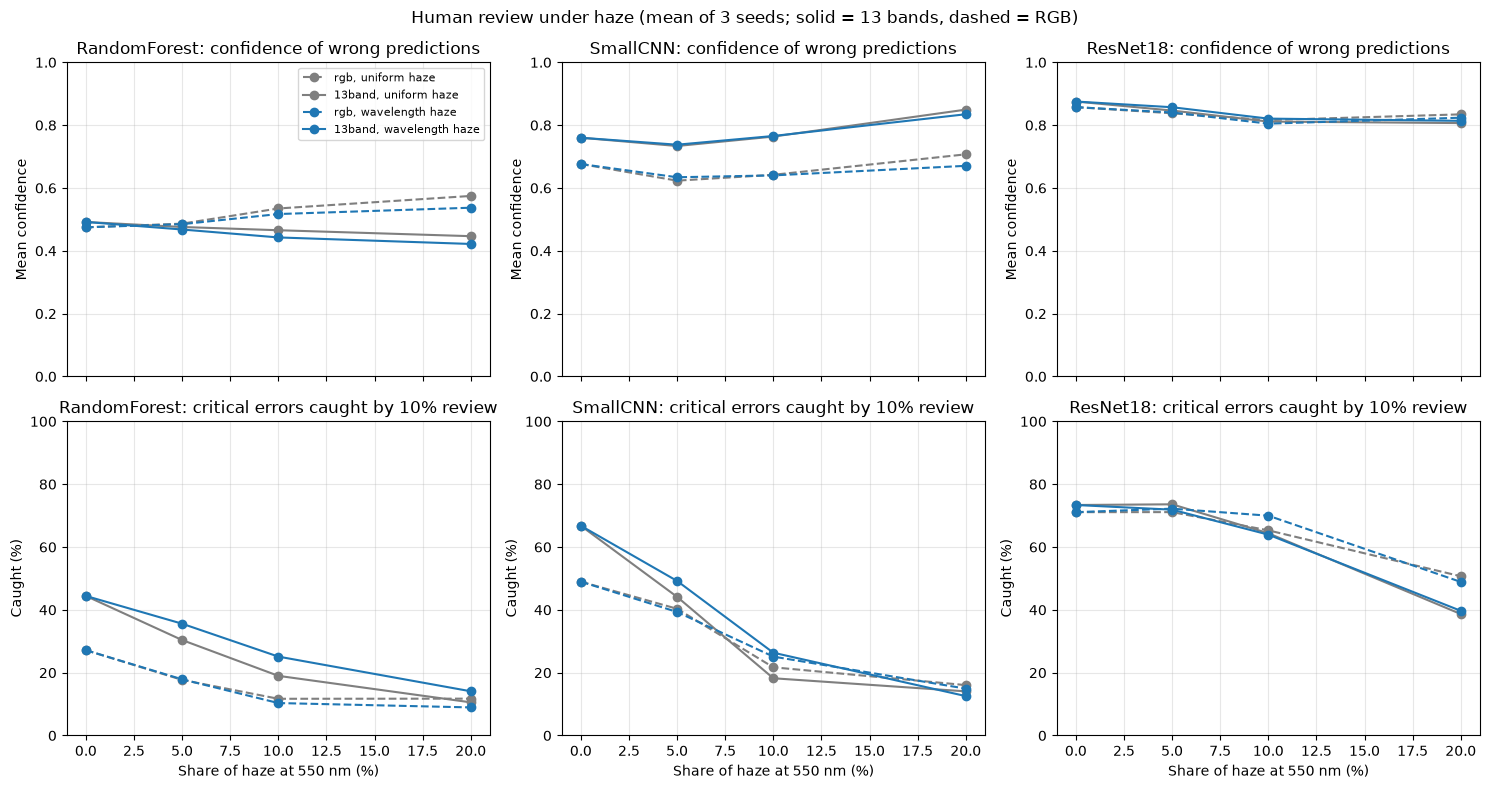

In [5]:
fig, axes = plt.subplots(2, len(MODELS), figsize=(15, 8), sharex=True)
means = review_means.reset_index()
for col, model_name in enumerate(MODELS):
    for profile in PROFILES:
        for input_type in INPUTS:
            line = means[(means["model"] == model_name) & (means["profile"] == profile) & (means["input"] == input_type)].sort_values("haze_550")
            style = dict(marker="o", color=colours[profile], ls="-" if input_type == "13band" else "--")
            axes[0, col].plot(line["haze_550"] * 100, line["confidence_wrong"], label=f"{input_type}, {profile} haze", **style)
            axes[1, col].plot(line["haze_550"] * 100, line["critical_caught_by_review"] * 100, **style)
    axes[0, col].set(title=f"{model_name}: confidence of wrong predictions", ylabel="Mean confidence", ylim=(0, 1))
    axes[1, col].set(title=f"{model_name}: critical errors caught by 10% review", ylabel="Caught (%)",
                     xlabel="Share of haze at 550 nm (%)", ylim=(0, 100))
    for ax in axes[:, col]:
        ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Human review under haze (mean of 3 seeds; solid = 13 bands, dashed = RGB)")
fig.tight_layout()
fig.savefig(figures_dir / "haze_review.png", dpi=150, bbox_inches="tight")
plt.show()


**Claim.** Human review stops working as the haze thickens: the networks stay just as confident when they are wrong, so the least confident patches no longer contain the costly mistakes.

**Reasons.** A model's confidence is only a useful warning if it falls when the model is wrong. Haze changes the inputs in a way the models never saw in training, but their probabilities are computed as if the inputs were normal, so they do not signal the new uncertainty.

**Evidence.** The mean confidence of wrong predictions stays at 0.81 to 0.88 for the ResNet at every level, and rises for the 13-band CNN from 0.76 (clean) to 0.85 (20% uniform haze). The share of critical errors caught by reviewing the 10% least confident patches falls for every model and input: for the ResNet from 71 to 73% (clean) to 64 to 70% at 10% haze and 39 to 51% at 20%; for the CNN from 49 to 67% to 13 to 16% at 20%; for the random forest from 27 to 44% to 9 to 14%. At 20%, the 13-band ResNet catches fewer of its critical errors (39 to 40%) than the RGB ResNet (49 to 51%).

**Warrant.** The reject option works by leaving the cases the model is least sure about to a human (Bishop, section 1.5.3, page 42). It assumes that the model's confidence reflects its chance of being wrong; when confidence stays high on wrong predictions, the rule sends the wrong patches to review.

**Counterargument.** The 10% review share is fixed, while the number of mistakes grows with the haze, so even a perfect ranking could not catch them all at 20%. We accept this, but the confidence of wrong predictions shows the same thing without depending on the review share: the networks do not become less sure. For an insurer, this means images should be checked for haze before the model is used, for example with a cloud and haze mask, instead of relying on the model's own confidence.

## 8. Where do hazy patches go?

Section 4 showed that from 40% haze the ResNet's critical-error rate falls again while its accuracy keeps falling. That can only happen if the wrong answers go to classes that are cheap in our cost matrix. In the prototype, a hazy AnnualCrop patch was called SeaLake by both ResNets, and predicting SeaLake costs 2 points for every true class, so it is never a critical error. This section asks two questions:

1. **Which class do the models answer as the haze thickens?** For every saved model and haze condition we count the share of test patches predicted as each class. If one class takes most patches, the model has a default answer for hazy images.
2. **Is the true class still in the hazy image?** We forbid SeaLake as an answer and take each model's best other class. If accuracy then recovers, the information about the land cover survives the haze and SeaLake is only a default; if it does not, the haze has removed the information. Both accuracies are measured on the test patches whose true class is not SeaLake, because a model that cannot answer SeaLake is always wrong on real lakes.

Forbidding SeaLake is a check, not a fix: real regions contain lakes, so a working system must keep the class. We run all 18 models, both haze profiles and all levels, as in section 3, so the results can be compared with sections 4 and 5. This cell predicts the test set again with the class probabilities (section 3 only kept the predicted class), so it takes about as long as section 3. It needs only the setup cell.

In [2]:
SEALAKE = CLASS_NAMES.index("SeaLake")
other_patches = y_true != SEALAKE  # true class is not SeaLake
haze_conditions = [("none", 0.0)] + [(profile, strength) for profile in PROFILES for strength in HAZE_LEVELS]

destination_rows = []
for model_name in MODELS:
    for input_type in INPUTS:
        for seed in SEEDS:
            start = time.time()
            model = load_saved_model(models_dir, model_name, input_type, seed, device)
            for profile, strength in haze_conditions:
                haze_profile = "uniform" if profile == "none" else profile  # no haze: strength 0
                proba = hazy_probabilities(model_name, model, test_rows, cache, band_stats, input_type,
                                           strength, haze_profile, airlight, device)
                y_pred = proba.argmax(axis=1)
                # best class other than SeaLake
                proba_no_sealake = proba.copy()
                proba_no_sealake[:, SEALAKE] = -1
                y_pred_no_sealake = proba_no_sealake.argmax(axis=1)
                row = {"model": model_name, "input": input_type, "seed": seed, "profile": profile, "haze_550": strength,
                       "accuracy": (y_pred == y_true).mean(),
                       "critical_error_rate": critical[y_true, y_pred].mean(),
                       # on the patches whose true class is not SeaLake
                       "accuracy_other": (y_pred == y_true)[other_patches].mean(),
                       "accuracy_other_no_sealake": (y_pred_no_sealake == y_true)[other_patches].mean(),
                       "critical_other": critical[y_true, y_pred][other_patches].mean(),
                       "critical_other_no_sealake": critical[y_true, y_pred_no_sealake][other_patches].mean()}
                for class_id, name in enumerate(CLASS_NAMES):
                    row[f"share_{name}"] = (y_pred == class_id).mean()
                destination_rows.append(row)
            print(f"{model_name} {input_type} seed {seed}: {time.time() - start:.0f} s")

haze_destinations = pd.DataFrame(destination_rows)
haze_destinations.to_csv(results_dir / "haze_destinations.csv", index=False)

# check: the predictions are the same as in section 3
check = haze_destinations.merge(pd.read_csv(results_dir / "haze_runs.csv"), on=["model", "input", "seed", "profile", "haze_550"],
                                suffixes=("", "_section3"))
assert len(check) == len(haze_destinations)
print("Largest difference to section 3, accuracy:", np.abs(check["accuracy"] - check["accuracy_section3"]).max(),
      "| critical-error rate:", np.abs(check["critical_error_rate"] - check["critical_error_rate_section3"]).max())

RandomForest rgb seed 0: 17 s
RandomForest rgb seed 1: 15 s
RandomForest rgb seed 2: 15 s
RandomForest 13band seed 0: 14 s
RandomForest 13band seed 1: 15 s
RandomForest 13band seed 2: 15 s
SmallCNN rgb seed 0: 18 s
SmallCNN rgb seed 1: 16 s
SmallCNN rgb seed 2: 17 s
SmallCNN 13band seed 0: 19 s
SmallCNN 13band seed 1: 19 s
SmallCNN 13band seed 2: 19 s
ResNet18 rgb seed 0: 158 s
ResNet18 rgb seed 1: 172 s
ResNet18 rgb seed 2: 177 s
ResNet18 13band seed 0: 247 s
ResNet18 13band seed 1: 249 s
ResNet18 13band seed 2: 250 s
Largest difference to section 3, accuracy: 0.0 | critical-error rate: 0.0


### 8.1 Which class do the models answer?

The table gives, for each model and condition, the class predicted most often and its share of the test patches (mean of the three seeds). On the clear test set, SeaLake is the true class of about one patch in ten, so a much larger share means the model sends other land cover there.

Share of SeaLake among the true test classes: 11.1%


profile                                    uniform                       \
                                    most_predicted  share share_SeaLake   
model        input  haze_550                                              
RandomForest 13band 0.00                AnnualCrop  0.125         0.111   
                    0.01                AnnualCrop  0.126         0.111   
                    0.02                AnnualCrop  0.129         0.110   
                    0.05                AnnualCrop  0.137         0.107   
                    0.10             PermanentCrop  0.167         0.103   
                    0.20             PermanentCrop  0.232         0.090   
                    0.40                AnnualCrop  0.430         0.000   
                    0.63      HerbaceousVegetation  0.595         0.000   
             rgb    0.00               Residential  0.140         0.118   
                    0.01               Residential  0.145         0.118   
                    0.02               Residential  0.151         0.124   
                    0.05                AnnualCrop  0.181         0.150   
                    0.10                   SeaLake  0.253         0.253   
                    0.20                AnnualCrop  0.260         0.258   
                    0.40                AnnualCrop  0.482         0.281   
                    0.63                AnnualCrop  0.495         0.402   
ResNet18     13band 0.00                    Forest  0.116         0.111   
                    0.01                    Forest  0.116         0.111   
                    0.02                    Forest  0.116         0.111   
                    0.05                AnnualCrop  0.115         0.111   
                    0.10      HerbaceousVegetation  0.128         0.112   
                    0.20      HerbaceousVegetation  0.159         0.120   
                    0.40                AnnualCrop  0.389         0.259   
                    0.63                   SeaLake  0.829         0.829   
             rgb    0.00                AnnualCrop  0.115         0.111   
                    0.01                AnnualCrop  0.115         0.111   
                    0.02                AnnualCrop  0.115         0.111   
                    0.05                AnnualCrop  0.116         0.111   
                    0.10                AnnualCrop  0.118         0.115   
                    0.20                   SeaLake  0.173         0.173   
                    0.40                   SeaLake  0.477         0.477   
                    0.63                   SeaLake  0.992         0.992   
SmallCNN     13band 0.00                AnnualCrop  0.116         0.111   
                    0.01                AnnualCrop  0.118         0.111   
                    0.02                AnnualCrop  0.120         0.111   
                    0.05                AnnualCrop  0.134         0.107   
                    0.10      HerbaceousVegetation  0.253         0.049   
                    0.20      HerbaceousVegetation  0.467         0.000   
                    0.40      HerbaceousVegetation  0.675         0.000   
                    0.63      HerbaceousVegetation  0.776         0.000   
             rgb    0.00                    Forest  0.120         0.110   
                    0.01                AnnualCrop  0.119         0.111   
                    0.02                AnnualCrop  0.124         0.112   
                    0.05                AnnualCrop  0.148         0.118   
                    0.10                AnnualCrop  0.194         0.145   
                    0.20                   SeaLake  0.269         0.269   
                    0.40                   SeaLake  0.327         0.327   
                    0.63                   SeaLake  0.362         0.362   

profile                                 wavelength                       
                                    most_predicted  share share_SeaLake  
model        input  haze_5

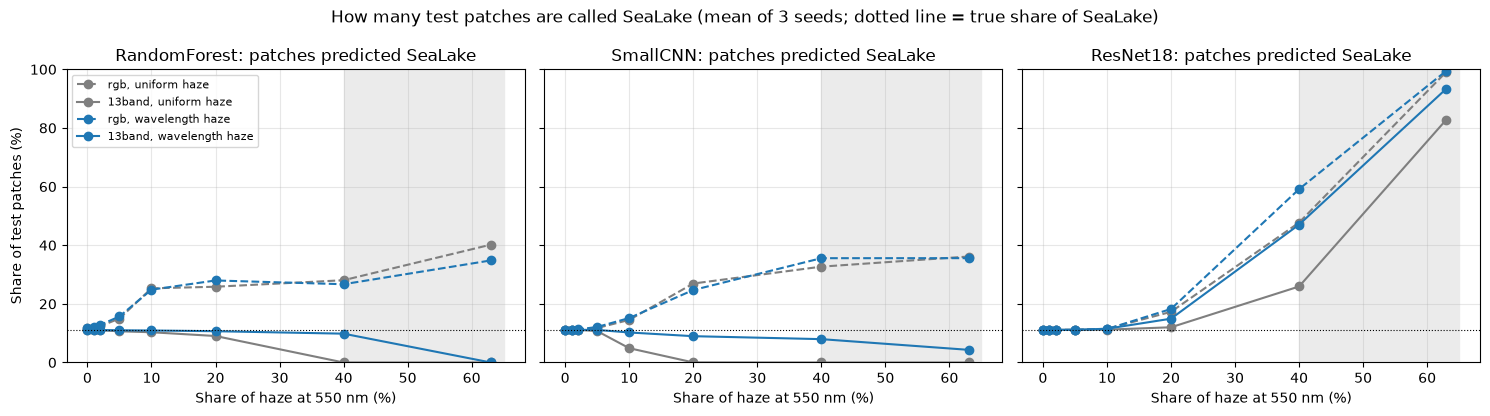

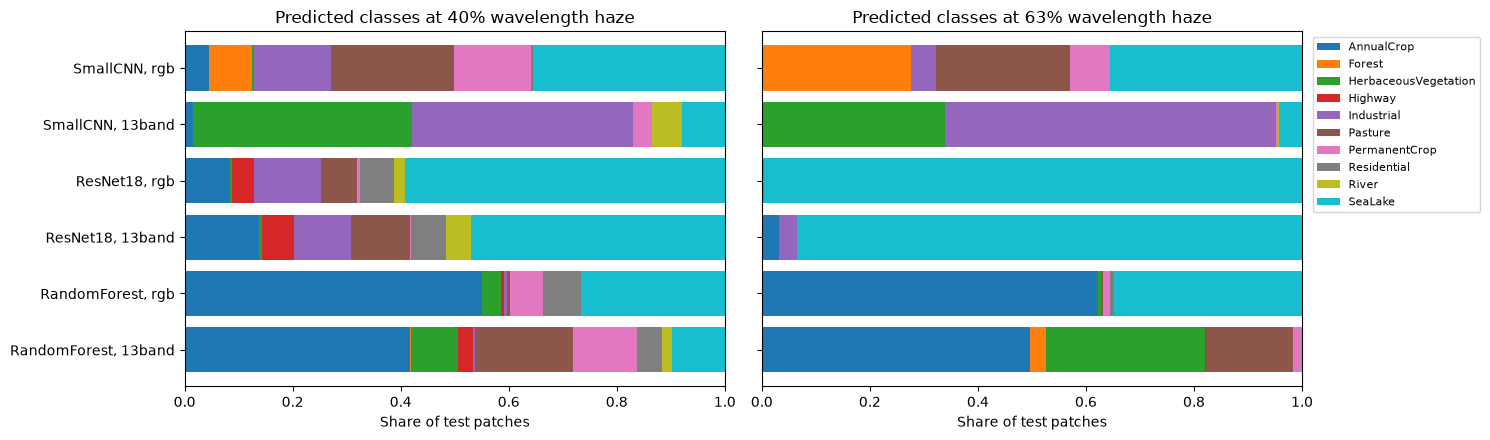

In [3]:
# read the saved results, so this part can run without the cell above
haze_destinations = pd.read_csv(results_dir / "haze_destinations.csv")
share_columns = [f"share_{name}" for name in CLASS_NAMES]
colours = {"uniform": "tab:grey", "wavelength": "tab:blue"}  # as in section 4
print(f"Share of SeaLake among the true test classes: {(y_true == SEALAKE).mean():.1%}")

clean = haze_destinations[haze_destinations["profile"].eq("none")]
destinations = pd.concat([haze_destinations[~haze_destinations["profile"].eq("none")]] + [clean.assign(profile=p) for p in PROFILES])
shares = destinations.groupby(["model", "input", "profile", "haze_550"])[share_columns].mean()
top = pd.DataFrame({"most_predicted": shares.idxmax(axis=1).str.replace("share_", ""),
                    "share": shares.max(axis=1).round(3),
                    "share_SeaLake": shares["share_SeaLake"].round(3)})
display(top.unstack(["profile"]).reorder_levels([1, 0], axis=1).sort_index(axis=1))

fig, axes = plt.subplots(1, len(MODELS), figsize=(15, 4.2), sharey=True)
for col, model_name in enumerate(MODELS):
    ax = axes[col]
    for profile in PROFILES:
        for input_type in INPUTS:
            line = shares.loc[(model_name, input_type, profile)]["share_SeaLake"]
            ax.plot(line.index * 100, line.values * 100, marker="o", color=colours[profile],
                    ls="-" if input_type == "13band" else "--", label=f"{input_type}, {profile} haze")
    ax.axhline((y_true == SEALAKE).mean() * 100, color="black", lw=0.8, ls=":")
    ax.axvspan(40, 65, color="0.92", zorder=0)
    ax.set(title=f"{model_name}: patches predicted SeaLake", xlabel="Share of haze at 550 nm (%)", ylim=(0, 100))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Share of test patches (%)")
axes[0].legend(fontsize=8)
fig.suptitle("How many test patches are called SeaLake (mean of 3 seeds; dotted line = true share of SeaLake)")
fig.tight_layout()
fig.savefig(figures_dir / "haze_sealake_share.png", dpi=150, bbox_inches="tight")
plt.show()

# all classes at the two heaviest levels, wavelength haze
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, strength in zip(axes, (0.40, 0.63)):
    table = shares.xs(("wavelength", strength), level=["profile", "haze_550"])
    table.columns = CLASS_NAMES
    table.index = [f"{m}, {i}" for m, i in table.index]
    table.plot.barh(stacked=True, ax=ax, legend=False, colormap="tab10", width=0.8)
    ax.set(title=f"Predicted classes at {strength:.0%} wavelength haze", xlabel="Share of test patches", xlim=(0, 1))
axes[1].legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
fig.savefig(figures_dir / "haze_predicted_classes.png", dpi=150, bbox_inches="tight")
plt.show()

**Claim.** Under heavy haze, the RGB models and both ResNets fall back on SeaLake, while the 13-band random forest and CNN collapse into land classes instead.

**Reasons.** SeaLake is the true class of 11.1% of the test patches, so a much larger share means other land cover is sent there. Our hypothesis for the split between inputs: water is the only class that is dark in the near-infrared and short-wave infrared bands. Haze brightens those bands too (the airlight is bright in every band), so to a model that sees all 13 bands a hazy patch does not look like water. A model that sees only bands 4, 3 and 2 sees a pale, smooth, bluish patch, which is closest to SeaLake. The 13-band ResNet still ends at SeaLake at the heaviest level; its first layer started from the RGB filters (notebook 05), so it may lean more on the visible bands. We have not tested either explanation.

**Evidence.** At 20% haze, the RGB random forest calls 26 to 28% of the test patches SeaLake, the RGB CNN 25 to 27% and the RGB ResNet 17 to 18%. At 40%, the RGB ResNet calls 48 to 59% SeaLake and the 13-band ResNet 26 to 47%; at 63%, 99 to 100% and 83 to 93%. The 13-band random forest calls at most 10% SeaLake at 40% and none at 63%; its patches go to AnnualCrop (42 to 50%) or, under uniform haze at 63%, to HerbaceousVegetation (60%). The 13-band CNN calls 0 to 9% SeaLake from 20% haze on; its patches go to HerbaceousVegetation (up to 78%) or, under wavelength haze from 40%, to Industrial (41 to 61%).

**Warrant.** A model that puts most inputs into one class once the inputs move away from its training data has a default answer for inputs it does not recognise. Which class becomes the default depends on what the model learned, so it can differ between models and inputs.

**Counterargument.** From 40% the models have failed (section 4), so these shares describe how the models fail rather than usable predictions. They still matter for an insurer, because the class the failures go to decides what they cost: SeaLake costs 2 points against every true class, while AnnualCrop or HerbaceousVegetation for the wrong land cover can be critical.

### 8.2 Is the true class still in the hazy image?

Accuracy on the test patches whose true class is not SeaLake, as the models answer (solid) and with SeaLake forbidden (dotted). The gap between the two lines is the share of patches whose true class was the model's best answer apart from SeaLake. The table adds the critical-error rate on the same patches, because forbidding the cheap SeaLake answer shows which errors it was hiding.

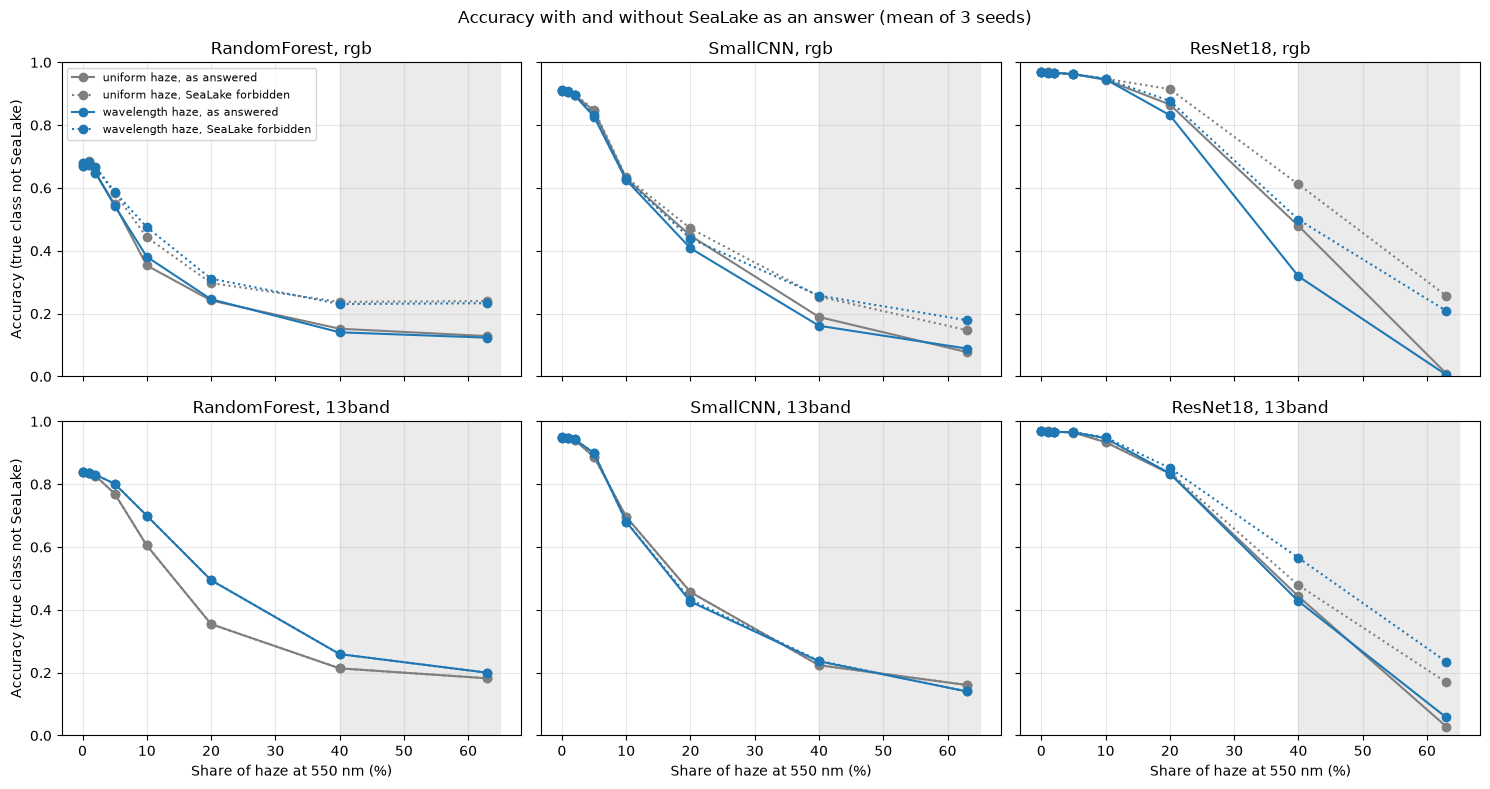

accuracy_other                              \
haze_550                                 0.00   0.10   0.20   0.40   0.63   
model        input  profile                                                 
RandomForest 13band uniform             0.840  0.605  0.355  0.214  0.182   
                    wavelength          0.840  0.700  0.495  0.259  0.200   
             rgb    uniform             0.669  0.353  0.242  0.152  0.128   
                    wavelength          0.669  0.381  0.246  0.141  0.123   
ResNet18     13band uniform             0.968  0.934  0.833  0.443  0.028   
                    wavelength          0.968  0.946  0.834  0.427  0.058   
             rgb    uniform             0.969  0.945  0.866  0.479  0.009   
                    wavelength          0.969  0.946  0.832  0.319  0.005   
SmallCNN     13band uniform             0.949  0.696  0.456  0.224  0.161   
                    wavelength          0.949  0.681  0.426  0.236  0.140   
             rgb    uniform             0.910  0.630  0.448  0.189  0.078   
                    wavelength          0.910  0.625  0.408  0.161  0.089   

                               accuracy_other_no_sealake                       \
haze_550                                            0.00   0.10   0.20   0.40   
model        input  profile                                                     
RandomForest 13band uniform                        0.840  0.605  0.355  0.214   
                    wavelength                     0.840  0.700  0.495  0.259   
             rgb    uniform                        0.680  0.443  0.297  0.237   
                    wavelength                     0.680  0.475  0.311  0.230   
ResNet18     13band uniform                        0.968  0.934  0.838  0.479   
                    wavelength                     0.968  0.949  0.851  0.566   
             rgb    uniform                        0.969  0.948  0.915  0.612   
                    wavelength                     0.969  0.948  0.877  0.499   
SmallCNN     13band uniform                        0.949  0.696  0.456  0.224   
                    wavelength                     0.949  0.681  0.432  0.238   
             rgb    uniform                        0.911  0.634  0.471  0.255   
                    wavelength                     0.911  0.629  0.438  0.258   

                                      critical_other                       \
haze_550                         0.63           0.00   0.10   0.20   0.40   
model        input  profile                                                 
RandomForest 13band uniform     0.182          0.109  0.283  0.483  0.616   
                    wavelength  0.200          0.109  0.214  0.395  0.578   
             rgb    uniform     0.240          0.185  0.284  0.391  0.471   
                    wavelength  0.233          0.185  0.271  0.387  0.500   
ResNet18     13band uniform     0.169          0.028  0.055  0.141  0.305   
                    wavelength  0.235          0.028  0.039  0.108  0.121   
             rgb    uniform     0.257          0.027  0.043  0.057  0.095   
                    wavelength  0.209          0.027  0.039  0.068  0.116   
SmallCNN     13band uniform     0.161          0.039  0.199  0.355  0.629   
                    wavelength  0.140          0.039  0.167  0.338  0.409   
             rgb    uniform     0.147          0.057  0.255  0.214  0.392   
                    wavelength  0.179          0.057  0.183  0.218  0.357   

                                      critical_other_no_sealake                \
haze_550                         0.63                      0.00   0.10   0.20   
model        input  profile                                                     
RandomForest 13band uniform     0.636                     0.109  0.283  0.483   
                    wavelength  0.625                     0.109  0.215  0.396   
             rgb    uniform     0.445                     0.189  0.341  0.483   
                 

In [4]:
measures = ["accuracy_other", "accuracy_other_no_sealake", "critical_other", "critical_other_no_sealake"]
means_other = destinations.groupby(["model", "input", "profile", "haze_550"])[measures].mean()

fig, axes = plt.subplots(len(INPUTS), len(MODELS), figsize=(15, 8), sharex=True, sharey=True)
for row, input_type in enumerate(INPUTS):
    for col, model_name in enumerate(MODELS):
        ax = axes[row, col]
        for profile in PROFILES:
            line = means_other.loc[(model_name, input_type, profile)]
            ax.plot(line.index * 100, line["accuracy_other"], marker="o", color=colours[profile], ls="-",
                    label=f"{profile} haze, as answered")
            ax.plot(line.index * 100, line["accuracy_other_no_sealake"], marker="o", color=colours[profile], ls=":",
                    label=f"{profile} haze, SeaLake forbidden")
        ax.axvspan(40, 65, color="0.92", zorder=0)
        ax.set(title=f"{model_name}, {input_type}", ylim=(0, 1))
        ax.grid(alpha=0.3)
        if col == 0:
            ax.set_ylabel("Accuracy (true class not SeaLake)")
        if row == len(INPUTS) - 1:
            ax.set_xlabel("Share of haze at 550 nm (%)")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Accuracy with and without SeaLake as an answer (mean of 3 seeds)")
fig.tight_layout()
fig.savefig(figures_dir / "haze_without_sealake.png", dpi=150, bbox_inches="tight")
plt.show()

levels = [0.0, 0.10, 0.20, 0.40, 0.63]
display(means_other[means_other.index.get_level_values("haze_550").isin(levels)]
        .unstack("haze_550").round(3))

**Claim.** Forbidding SeaLake recovers only part of the accuracy, so heavy haze removes most of the information about the land cover. What SeaLake mainly hides is critical errors.

**Reasons.** If the true class were still the model's clear second choice behind SeaLake, the accuracy with SeaLake forbidden would come close to the clear accuracy (97% for the ResNets on these patches). The gap that remains shows how much information the haze has removed.

**Evidence.** Up to 20% haze, forbidding SeaLake adds at most 5 points (RGB ResNet under uniform haze: 86.6% to 91.5%). At 40%, the RGB ResNet rises from 32 to 48% to 50 to 61% and the 13-band ResNet from 43 to 44% to 48 to 57%; at 63%, from below 1% to 21 to 26% and from 3 to 6% to 17 to 24%. The RGB random forest and CNN gain 7 to 11 points at 63%; the 13-band random forest and CNN change by less than 1 point, because they hardly answer SeaLake. The critical-error rate of the ResNets at 63% rises from 0% (RGB) and 1 to 11% (13 bands) to 50 to 70% once SeaLake is forbidden, as high as the 49 to 68% of the 13-band random forest and CNN. The AnnualCrop patch shown in the prototype was recovered completely even at 63%; at that level this happens for only one patch in four or five.

**Warrant.** The best answer apart from SeaLake shows what the model would say without its default. If that answer is mostly wrong, the default was not hiding a correct answer.

**Counterargument.** The second choice can itself be a default (for example AnnualCrop for the hazy RGB random forest), so the recovered accuracy is only a rough measure of the information left. And a real region contains lakes, so SeaLake cannot be removed in practice. The result for an insurer is that the low critical-error rate of the ResNet under heavy haze is not safety: heavy haze has to be caught before the model (section 7), not left to the cost matrix. This also explains part of section 5's finding that the 13-band networks make more critical errors under haze than their RGB versions: the RGB networks send more hazy patches to the cheap SeaLake answer. With SeaLake forbidden the gap narrows (CNN at 20% uniform haze: RGB 21.4% to 30.1% against 35.5% for 13 bands) and for the CNN under 40% wavelength haze it reverses (49.5% RGB against 41.1% for 13 bands).

## Summary

- Haze was simulated with the standard model of a hazy image, with more haze in short wavelengths (Ångström law) and a uniform profile as a control, at seven levels from 1% to 63% haze in green light. The first version, which used real aerosol optical depths, made the haze far too strong and was replaced (section 2).
- All 18 saved models reproduce their clean predictions exactly before haze is added.
- Up to 2% haze, nothing changes. From 5%, the random forest and CNN lose accuracy quickly; the pretrained ResNet holds up to about 10% (94 to 95%) and is still at 85 to 88% at 20%.
- **SQ4.** The 13-band advantage holds under light haze for the random forest and the CNN, and lasts longer under wavelength-dependent haze than under uniform haze (CNN at 5%: +6.4 points only under wavelength haze). For the ResNet, the 13 bands only help under heavy wavelength-dependent haze (+9.7 points at 40%), when both inputs are already below 50%.
- Under heavier haze (20% and more), the 13-band CNN and ResNet make more critical errors than their RGB versions. Part of this gap comes from the RGB models sending hazy patches to the cheap SeaLake answer (section 8). Haze therefore makes human review more important, whatever the input.
- Under heavy haze the ResNets and the RGB random forest and CNN fall back on SeaLake (at 63%, 83 to 100% of the patches for the ResNets), while the 13-band random forest and CNN collapse into land classes. Because SeaLake is a cheap answer in our cost matrix, this hides critical errors: with SeaLake forbidden, the ResNets' critical-error rate at 63% is 50 to 70%. Forbidding SeaLake recovers only part of the accuracy (ResNets at 63%: from below 6% to 17 to 26%), so heavy haze removes most of the information rather than only hiding it (section 8).
- Haze does not make grassland look like forest, so it does not explain the HerbaceousVegetation-to-Forest mistakes of notebook 06.
- Human review loses its value under haze: the networks stay as confident when wrong, so a 10% review catches 39 to 51% of the ResNet's critical errors at 20% haze, against 71 to 73% on clear images. Hazy images should be screened before the model is used.

## References

Course: AI, Machine Learning & Analytics, IE University, fall 2026 (Prof. P. Delgado-Santos). Course files are cited by file name with the slide, page or section used.

**Course material**

- `lecture_15_intro_to_generative_models.pdf`, lecture slides. Used: slide 8.
- Bishop, C. M. (2006). *Pattern Recognition and Machine Learning*. Springer. Course textbook. Used: section 1.5.3, page 42.

**External sources**

- Helber, P., Bischke, B., Dengel, A. & Borth, D. (2019). EuroSAT: A novel dataset and deep learning benchmark for land use and land cover classification. *IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing*, 12(7), 2217–2226. https://doi.org/10.1109/JSTARS.2019.2918242. Used for: the dataset.
- He, K., Zhang, X., Ren, S. & Sun, J. (2016). Deep residual learning for image recognition. *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 770–778. Used for: ResNet18 tested under haze.
- He, K., Sun, J. & Tang, X. (2011). Single image haze removal using dark channel prior. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 33(12), 2341–2353. Used for: haze model, equation 1.
- Institute for Earth Science Research and Education. The Ångström exponent. https://www.instesre.org/Aerosols/angstrom.htm. Used for: Ångström exponent.
- Penn State University. METEO 300: Fundamentals of Atmospheric Science, section 6.10. Used for: Beer–Lambert law.
- U.S. Geological Survey. USGS EROS Archive: Sentinel-2. https://www.usgs.gov/centers/eros/science/usgs-eros-archive-sentinel-2. Used for: band wavelengths.
- Efron, B. & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall. Used for: bootstrap intervals, chapters 6 and 13.
- Field, C. A. & Welsh, A. H. (2007). Bootstrapping clustered data. *Journal of the Royal Statistical Society: Series B*, 69(3), 369–390. https://doi.org/10.1111/j.1467-9868.2007.00593.x. Used for: bootstrapping clustered data.